# 04 · Evaluate on the sealed test set (unseen car models)

In [2]:
import os, sys
REPO_URL = "https://github.com/YUPWE/car-size.git"
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = "/content/drive/MyDrive/car-size"
    if not os.path.exists(ROOT):
        !git clone {REPO_URL} {ROOT}
    os.chdir(ROOT)
    !git pull -q
    !pip install -q imagehash==4.3.2
    os.environ["CARS_DATA_DIR"] = "/content/cars_data"
else:
    ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
    os.chdir(ROOT)
sys.path.insert(0, ROOT)
os.makedirs("results", exist_ok=True)
os.makedirs("weights", exist_ok=True)
QUICK = os.environ.get("QUICK", "0") == "1"
print("Working in", os.getcwd(), "| QUICK =", QUICK)

Mounted at /content/drive
Working in /content/drive/MyDrive/car-size | QUICK = False


In [3]:
import json, shutil, numpy as np, pandas as pd, torch, matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from sklearn.metrics import (f1_score, accuracy_score, precision_score, recall_score, average_precision_score,
                             precision_recall_curve, confusion_matrix, ConfusionMatrixDisplay)
from src import data
from src.data import CLASSES, CarDataset, get_transforms
from src.model import build_resnet18, predict_probs, get_device
from src.clip_gate import ClipZeroShot, load_pil
from src.system import decide, mix, load_config, save_config, BIG

data.download()
device = get_device()
cfg = load_config(); W, OOS_T = cfg["w"], cfg["oos_threshold"]
print("from notebook 03:", cfg)

splits = {s: data.load_split(s) for s in ["val", "test"]}
if QUICK: splits = {s: d.sample(32, random_state=0).reset_index(drop=True) for s, d in splits.items()}

def load_model(path):
    m = build_resnet18(freeze_backbone=False, pretrained=False)
    m.load_state_dict(torch.load(path, map_location=device)); return m.to(device)
models = {"frozen": load_model("weights/resnet18_frozen.pt"), "finetuned": load_model("weights/resnet18_finetuned.pt")}
clip = ClipZeroShot(device=device)

P = {}
for s, d in splits.items():
    loader = DataLoader(CarDataset(d, get_transforms(False)), batch_size=128, num_workers=2)
    P[s] = {"y": np.array([CLASSES.index(l) for l in d.label])}
    for k, m in models.items():
        P[s][k], _ = predict_probs(m, loader, device)
    P[s]["clip"], P[s]["oos"] = clip(load_pil(f"{data.IMG_DIR}/{p}" for p in d.path))
    P[s]["mixed"] = mix(P[s]["finetuned"], P[s]["clip"], W)

Unzipping cached images ...
from notebook 03: {'w': 0.8, 'oos_threshold': 0.3, 'clip_model': 'openai/clip-vit-base-patch16'}


config.json:   0%|          | 0.00/4.10k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  599MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  599MB            

... (3 outputs left out)

vocab.json:   0%|          | 0.00/961k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

## 1 · Choose the big-car threshold (validation only)

In [4]:
TARGET_RECALL = 0.95
yv, pv = P["val"]["y"], P["val"]["mixed"][:, BIG]
ts = np.round(np.arange(0.02, 0.99, 0.01), 2)
rec = np.array([recall_score(yv, pv >= t, zero_division=0) for t in ts])
prec = np.array([precision_score(yv, pv >= t, zero_division=0) for t in ts])
ok = ts[rec >= TARGET_RECALL]
BIG_T = float(ok.max()) if len(ok) else 0.02
save_config(big_threshold=BIG_T, target_recall_big=TARGET_RECALL)
i = int(np.where(ts == BIG_T)[0][0])
print(f"chosen big threshold = {BIG_T}: val recall(big) {rec[i]:.1%}, val precision(big) {prec[i]:.1%}")

chosen big threshold = 0.2: val recall(big) 95.2%, val precision(big) 93.6%


## 2 · Test set: model comparison

In [5]:
yt = P["test"]["y"]
rows = []
for name, key in [("CLIP zero-shot (no training)", "clip"), ("ResNet-18 frozen (baseline)", "frozen"),
                  ("ResNet-18 fine-tuned", "finetuned"), (f"Fine-tuned + CLIP mix (w={W})", "mixed")]:
    p = P["test"][key][:, BIG]; pred = (p >= 0.5).astype(int)
    rows.append({"model": name, "accuracy @0.5": accuracy_score(yt, pred), "F1(big) @0.5": f1_score(yt, pred),
                 "recall(big) @0.5": recall_score(yt, pred), "avg precision (PR-AUC)": average_precision_score(yt, p)})
table = pd.DataFrame(rows).round(3)
print(f"Test set: {len(yt)} images, {(yt == BIG).sum()} big, {len(set(splits['test'].group))} unseen car families")
print(table.to_string(index=False)); table.to_csv("results/test_comparison.csv", index=False)

Test set: 2189 images, 553 big, 21 unseen car families
                        model  accuracy @0.5  F1(big) @0.5  recall(big) @0.5  avg precision (PR-AUC)
 CLIP zero-shot (no training)          0.938         0.864             0.781                   0.904
  ResNet-18 frozen (baseline)          0.851         0.732             0.807                   0.822
         ResNet-18 fine-tuned          0.925         0.856             0.888                   0.935
Fine-tuned + CLIP mix (w=0.8)          0.928         0.861             0.888                   0.948


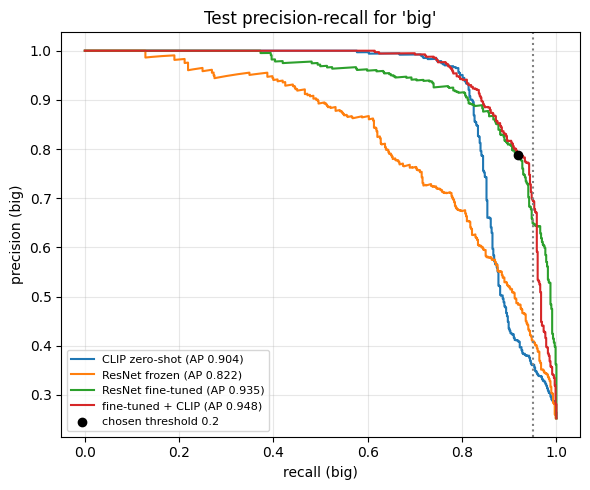

In [6]:
plt.figure(figsize=(6, 5))
for name, key in [("CLIP zero-shot", "clip"), ("ResNet frozen", "frozen"), ("ResNet fine-tuned", "finetuned"), ("fine-tuned + CLIP", "mixed")]:
    pr, rc, _ = precision_recall_curve(yt, P["test"][key][:, BIG])
    plt.plot(rc, pr, label=f"{name} (AP {average_precision_score(yt, P['test'][key][:, BIG]):.3f})")
pt = P["test"]["mixed"][:, BIG]
plt.scatter([recall_score(yt, pt >= BIG_T)], [precision_score(yt, pt >= BIG_T)], c="k", zorder=5, label=f"chosen threshold {BIG_T}")
plt.axvline(TARGET_RECALL, ls=":", c="gray")
plt.xlabel("recall (big)"); plt.ylabel("precision (big)"); plt.title("Test precision-recall for 'big'"); plt.legend(fontsize=8); plt.grid(alpha=.3)
plt.tight_layout(); plt.savefig("results/pr_curve.png", dpi=120); plt.show()

## 3 · Test set: the full system at the chosen threshold

test images                              2189
recall(big): big cars caught             91.9%
precision(big)                           78.9%
F1(big)                                  0.849
big cars sent to compact (missed)        45
small cars sent to big levels            136
real cars wrongly called 'not a car'     0.0%


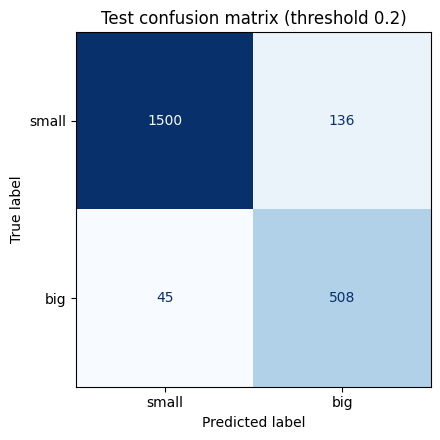

In [7]:
dec, p_big = decide(P["test"]["finetuned"], P["test"]["clip"], P["test"]["oos"], W, BIG_T, OOS_T)
dec = np.array(dec); truth = np.array([CLASSES[i] for i in yt])
car = dec != "not a car"
pred_big = (dec == "big")
summary = {
    "test images": len(dec),
    "recall(big): big cars caught": f"{recall_score(yt, pred_big):.1%}",
    "precision(big)": f"{precision_score(yt, pred_big):.1%}",
    "F1(big)": f"{f1_score(yt, pred_big):.3f}",
    "big cars sent to compact (missed)": int(((yt == BIG) & ~pred_big).sum()),
    "small cars sent to big levels": int(((yt != BIG) & pred_big).sum()),
    "real cars wrongly called 'not a car'": f"{(~car).mean():.1%}",
}
for k, v in summary.items(): print(f"{k:40s} {v}")
json.dump(summary, open("results/system_test_summary.json", "w"), indent=1)

fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay(confusion_matrix(yt, pred_big.astype(int), labels=[0, 1]), display_labels=CLASSES).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title(f"Test confusion matrix (threshold {BIG_T})"); plt.tight_layout(); plt.savefig("results/confusion_matrix.png", dpi=120); plt.show()

In [8]:
test_df = splits["test"].reset_index(drop=True).copy()
test_df["correct"] = (pred_big.astype(int) == yt)
by_body = test_df.groupby(["label", "body"]).correct.agg(["count", "mean"]).rename(columns={"mean": "accuracy"}).round(3)
print(by_body); by_body.to_csv("results/accuracy_by_body_type.csv")

                   count  accuracy
label body                        
big   Cab             82     0.988
      Minivan         81     0.988
      SUV            261     0.835
      Van            129     1.000
small Convertible    396     0.980
      Coupe          406     0.998
      Hatchback      403     0.767
      Sedan          431     0.923


## 4 · Failure images

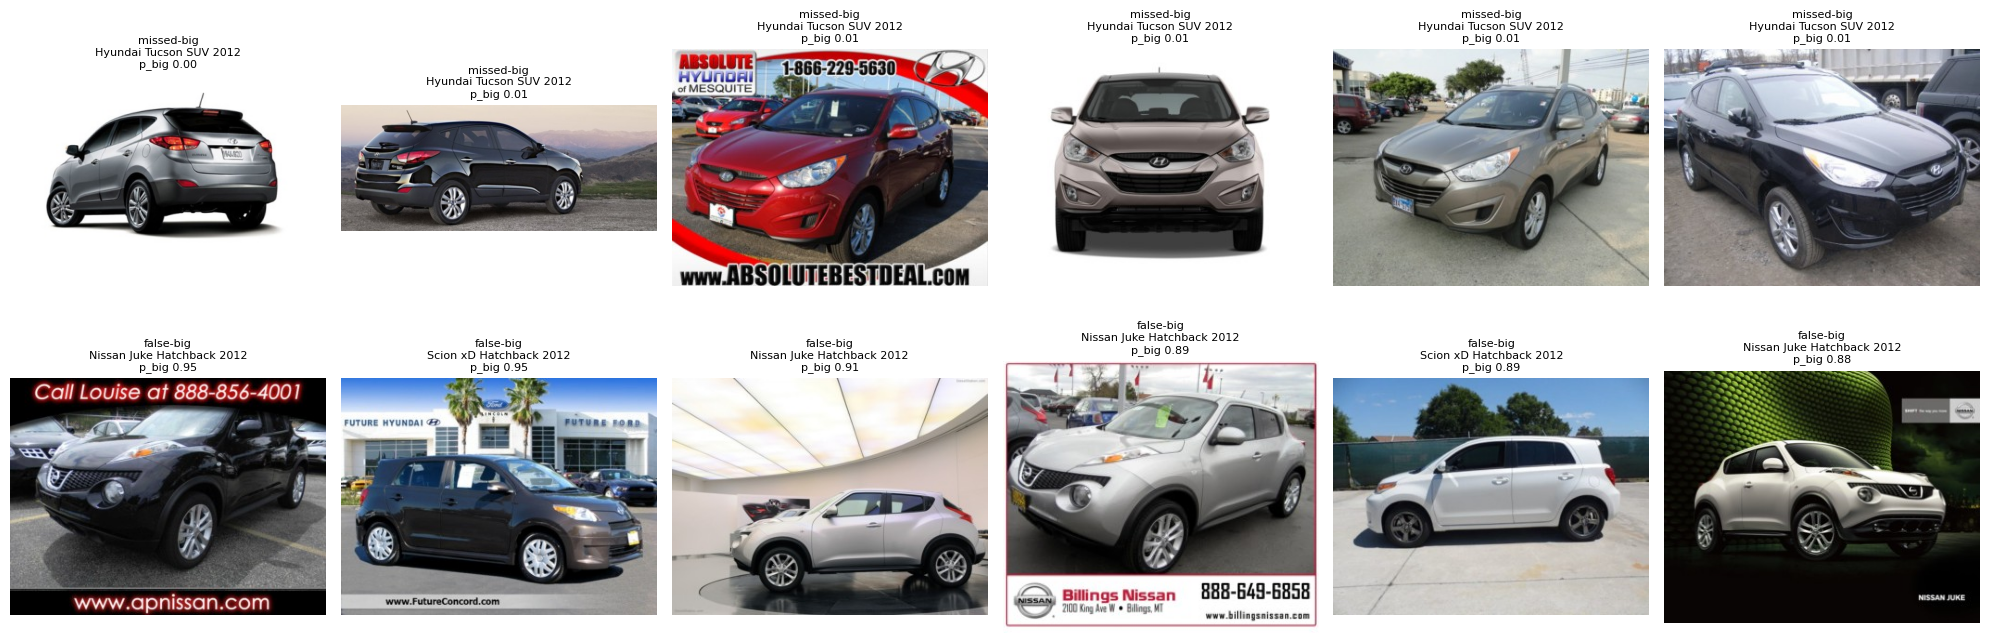

6 missed big + 6 false big saved
                      file                      model  p_big
     01_missed-big_SUV.jpg    Hyundai Tucson SUV 2012  0.004
     02_missed-big_SUV.jpg    Hyundai Tucson SUV 2012  0.008
     03_missed-big_SUV.jpg    Hyundai Tucson SUV 2012  0.010
     04_missed-big_SUV.jpg    Hyundai Tucson SUV 2012  0.011
     05_missed-big_SUV.jpg    Hyundai Tucson SUV 2012  0.011
     06_missed-big_SUV.jpg    Hyundai Tucson SUV 2012  0.013
07_false-big_Hatchback.jpg Nissan Juke Hatchback 2012  0.950
08_false-big_Hatchback.jpg    Scion xD Hatchback 2012  0.947
09_false-big_Hatchback.jpg Nissan Juke Hatchback 2012  0.910
10_false-big_Hatchback.jpg Nissan Juke Hatchback 2012  0.890
11_false-big_Hatchback.jpg    Scion xD Hatchback 2012  0.889
12_false-big_Hatchback.jpg Nissan Juke Hatchback 2012  0.877


In [9]:
shutil.rmtree("results/failures", ignore_errors=True); os.makedirs("results/failures")
fn = np.where((yt == BIG) & ~pred_big & car)[0]; fn = fn[np.argsort(p_big[fn])][:6]
fp = np.where((yt != BIG) & pred_big)[0];         fp = fp[np.argsort(-p_big[fp])][:6]
pick = [("missed-big", i) for i in fn] + [("false-big", i) for i in fp]
records = []
fig, axes = plt.subplots(2, 6, figsize=(20, 7)); axes = axes.ravel()
for k, (kind, i) in enumerate(pick):
    row = test_df.iloc[i]
    name = f"{k + 1:02d}_{kind}_{row.body}.jpg"
    shutil.copy(f"{data.IMG_DIR}/{row.path}", f"results/failures/{name}")
    records.append({"file": name, "model": row.model, "body": row.body, "true": row.label, "decision": dec[i],
                    "p_big": round(float(p_big[i]), 3), "cause": "", "fix": ""})
    axes[k].imshow(plt.imread(f"{data.IMG_DIR}/{row.path}"))
    axes[k].set_title(f"{kind}\n{row.model[:30]}\np_big {p_big[i]:.2f}", fontsize=8); axes[k].axis("off")
for a in axes[len(pick):]: a.axis("off")
plt.tight_layout(); plt.savefig("results/failures_overview.png", dpi=100); plt.show()
pd.DataFrame(records).to_csv("results/failures/failures.csv", index=False)
print(len(fn), "missed big +", len(fp), "false big saved")
print(pd.DataFrame(records)[["file", "model", "p_big"]].to_string(index=False))

## 5 · Numbers for the README

In [10]:
print(table.to_markdown(index=False))
print()
print(f"- Big-car threshold: **{BIG_T}** (highest value with validation recall(big) >= {TARGET_RECALL:.0%})")
print(f"- Not-a-car gate threshold: **{OOS_T}** · CLIP mixing weight w: **{W}**")
for k, v in summary.items(): print(f"- {k}: **{v}**")

| model                         |   accuracy @0.5 |   F1(big) @0.5 |   recall(big) @0.5 |   avg precision (PR-AUC) |
|:------------------------------|----------------:|---------------:|-------------------:|-------------------------:|
| CLIP zero-shot (no training)  |           0.938 |          0.864 |              0.781 |                    0.904 |
| ResNet-18 frozen (baseline)   |           0.851 |          0.732 |              0.807 |                    0.822 |
| ResNet-18 fine-tuned          |           0.925 |          0.856 |              0.888 |                    0.935 |
| Fine-tuned + CLIP mix (w=0.8) |           0.928 |          0.861 |              0.888 |                    0.948 |

- Big-car threshold: **0.2** (highest value with validation recall(big) >= 95%)
- Not-a-car gate threshold: **0.3** · CLIP mixing weight w: **0.8**
- test images: **2189**
- recall(big): big cars caught: **91.9%**
- precision(big): **78.9%**
- F1(big): **0.849**
- big cars sent to compact (missed